In [1]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from workload_data_loader import load_workload_instance

In [2]:
n, m, utilities, demands, capacities = load_workload_instance("multi_resource_n28_m2.txt")


df = pd.DataFrame({"utility": utilities, **{f"resource_{i+1}": demands[i] for i in range(m)}})
print(demands)

[[ 45.   0.  85. 150.  65.  95.  30.   0. 170.   0.  40.  25.  20.   0.
    0.  25.   0.   0.  25.   0. 165.   0.  85.   0.   0.   0.   0. 100.]
 [ 30.  20. 125.   5.  80.  25.  35.  73.  12.  15.  15.  40.   5.  10.
   10.  12.  10.   9.   0.  20.  60.  40.  50.  36.  49.  40.  19. 150.]]


In [3]:
def evaluate(solution):
    # m is the number of resource bounds, in this case it will be 2
    # sum(iterable, start), if no np.zeros, the weight will be out of bounds as a set
    weight = sum((demands[:, i] for i in solution), np.zeros(m))
    value = sum(utilities[i] for i in solution)
    return weight, value

def fits(weight):
    return np.all(weight <= capacities)  # checks if all the resources under the capacity

def penalized_score(solution, penalty_weight=2000):
    weight, value = evaluate(solution)
    excess = np.maximum(0, weight - capacities)  # overflow per resource
    return value - penalty_weight * np.sum(excess)


def hill_climbing(seed=None, penalty_weight=2000):
    if seed is None:
        solution = set()  # Set up an empty starting solution
    else:
        np.random.seed(seed)
        # Random starting subset (may be infeasible; penalty guides it to feasibility)
        solution = {i for i in range(n) if np.random.rand() < 0.5}

    history = []
    while True:
        current_score = penalized_score(solution, penalty_weight)
        history.append(current_score)
        best_neighbor = solution #convert to best neighbor and best value to compare
        best_score = current_score

        # Neighbors: add, remove, or swap one model
        for i in range(n):  #n: the number of models, in this case: 28
            if i not in solution:
                candidate = solution | {i}  # Add the neighbor
                score = penalized_score(candidate, penalty_weight)

                if score > best_score:
                    best_neighbor = candidate
                    best_score = score

            else:
                candidate = solution - {i}  # Remove
                score = penalized_score(candidate, penalty_weight)

                if score > best_score:
                    best_neighbor = candidate
                    best_score = score


                for j in range(n):
                    if j not in solution:
                        candidate = (solution - {i}) | {j}  # Swap the resources values
                        score = penalized_score(candidate, penalty_weight)

                        if score > best_score:
                            best_neighbor = candidate
                            best_score = score

        # Stop if no improvement
        if best_neighbor == solution:
            break

        solution = best_neighbor

    return solution, history

# Show result
solution, _ = hill_climbing()
weight, value = evaluate(solution)

print("Selected models:")
for i in sorted(solution):
    print("Model", i, "- Demands:", demands[:, i], "Utility:", utilities[i])

print("Total resource used:", weight, "/ Capacity:", capacities)
print("Total utility:", value)


Selected models:
Model 2 - Demands: [ 85. 125.] Utility: 22507.0
Model 4 - Demands: [65. 80.] Utility: 14148.0
Model 6 - Demands: [30. 35.] Utility: 4650.0
Model 7 - Demands: [ 0. 73.] Utility: 30800.0
Model 9 - Demands: [ 0. 15.] Utility: 4975.0
Model 10 - Demands: [40. 15.] Utility: 1160.0
Model 13 - Demands: [ 0. 10.] Utility: 11880.0
Model 18 - Demands: [25.  0.] Utility: 110.0
Model 20 - Demands: [165.  60.] Utility: 24355.0
Model 22 - Demands: [85. 50.] Utility: 11748.0
Model 23 - Demands: [ 0. 36.] Utility: 4550.0
Total resource used: [495. 499.] / Capacity: [500. 500.]
Total utility: 130883.0


In [4]:
results = []
times = []
histories = []
best_sol = None
best_val = -1

for run in range(20):
    t0 = time.perf_counter()
    sol, hist = hill_climbing(seed=run)
    times.append(time.perf_counter() - t0)

    weight, value = evaluate(sol)
    results.append(value)
    histories.append(hist)
    if value > best_val:
        best_val = value
        best_sol = sol

print("Best:", max(results))
print("Mean:", np.mean(results))
print("Median:", np.median(results))
print("Std:", np.std(results))
print(f"Mean runtime: {np.mean(times):.4f}s | Total runtime: {np.sum(times):.4f}s")
print("Best models:", sorted(best_sol))
print("Best resource used:", evaluate(best_sol)[0], "/", capacities)


Best: 129173.0
Mean: 117007.7
Median: 119121.0
Std: 9866.870928009548
Mean runtime: 0.0202s | Total runtime: 0.4050s
Best models: [2, 4, 6, 7, 9, 10, 12, 13, 16, 20, 22, 26]
Best resource used: [490. 497.] / [500. 500.]


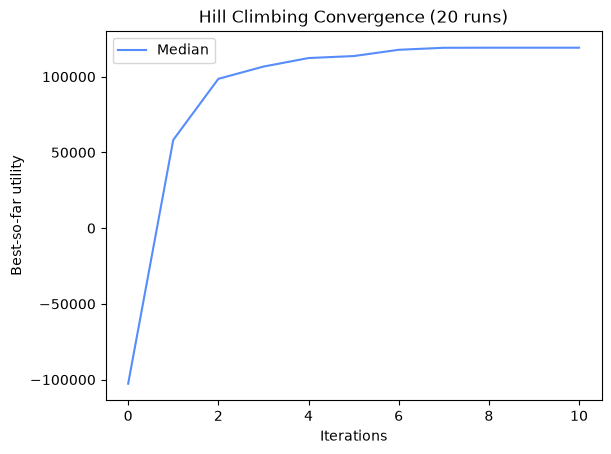

In [5]:
# Pad shorter runs with their final value so history is a 2D array (runs, iterations)
max_len = max(len(h) for h in histories) #max len of all runs (20)
history = np.array([h + [h[-1]] * (max_len - len(h)) for h in histories]) #fill an array with less iteration than the array have highest number of iterations to avoid errors of shapes when representing in graphs

best_so_far = np.maximum.accumulate(history, axis=1)
med = np.median(best_so_far, axis=0)
plt.plot(med, label="Median")
plt.xlabel("Iterations")
plt.ylabel("Best-so-far utility")
plt.title("Hill Climbing Convergence (20 runs)")
plt.legend()
plt.show()


#### Part 1: Baseline Discrete Local Search
For this part, I'm using a baseline local search (hill-climbing) to find best models to have best result. \
The model is a basic model with add and remove operators with a static constraint handling algorithm, and the reason why I choose local search because the dataset is small and stated that it is used for baseline local search, testing and validation, there is 1 problem of this model is that the randomize might not work, the model can be not improved everytime it runs as it shows no learning from times to times, for example, first iteration can give a good value/result, but it will give less value result in the next one, which consumes a lot of computation resources, and not use the resources to find a good solution. At the same time I have applied static penalty constrant to approach constraint handling, this constrant is easy to apply and preserve the result, however, the critical disadvange of this approach is that it needs its panalty weight choosen carefully.\

As the result of 20 runs (for-loop), the mean time that this model finds a solution is 0.0830s, total time to complete the for-loop is around 1.6s. The best models are 2, 4, 6, 7, 9, 10, 12, 13, 16, 20, 22 and 26 to generate the highest value, and also it nearly uses all resources with 490/500 and 497/500.

Regarding the convergence graph, in all 20 runs, the maximum iterations to find the best solution is 11 iterations. In the y-axis, it shows the best-so-far metrics, however, in iteration 1, it will have minus variable to go because some runs can exceed the capacity, which penalties hit it. Overall the graph show that best-so-far value gradually increased.

In [6]:
print(med)

[-102688.    58230.5   98560.5  106650.   112294.5  113590.5  117738.
  119066.   119121.   119121.   119121. ]


In [7]:
# Part 2: Genetic Algorithm on Instance 2 (n = 90, m = 5)
from workload_data_loader import load_workload_instance
n2, m2, utilities2, demands2, capacities2 = load_workload_instance("multi_resource_n90_m5 (1).txt")

population_size = 50 # 50 possible solutions
generations = 200
mutation_rate = 1 / n2   # flip ~1 bit per child on average

# Efficiency ratio for greedy repair (higher utility per normalized resource = better)
efficiency = utilities2 / np.sum(demands2 / capacities2[:, None], axis=0) #Original: value / capacity
drop_order = np.argsort(efficiency)   # worst efficiency in the first place of the array

def greedy_repair(chromosome):
    repaired = chromosome.copy()
    used_resources = np.dot(demands2, repaired)
    # Drop lowest-efficiency models until all constraints fit
    for i in drop_order:
        if np.all(used_resources <= capacities2):
            break
        if repaired[i] == 1:
            repaired[i] = 0
            used_resources = used_resources - demands2[:, i] #minus the resources that is switched to 0, when for loop again, compare the used resource with the capacities
    return repaired

def ga_fitness(chromosome):
    return np.dot(utilities2, chromosome) #calculate the value of the solution

def create_chromosome():
    return greedy_repair(np.random.randint(0, 2, size=n2)) #randomly create chromosome

def tournament_selection(population, k=3):
    idx = np.random.choice(len(population), size=k, replace=False) #choosing tournament of 3 candidates, returns the best candidate
    candidates = [population[i] for i in idx] #list of all candidates
    return max(candidates, key=ga_fitness)

def crossover(parent1, parent2):
    point = np.random.randint(1, n2)  #randomizing the index to crossover
    child1 = np.concatenate([parent1[:point], parent2[point:]])
    child2 = np.concatenate([parent2[:point], parent1[point:]])
    return child1, child2

def mutation(chromosome): #randomly flips from 0 to 1 to see new models
    for i in range(n2):
        if np.random.rand() < mutation_rate: #generate a random variable from 0 to 1, compare it with the mutation rate
            chromosome[i] = 1 - chromosome[i]
    return chromosome
    #the mutation rate is the probability of switching models in a solution

def genetic_algorithm(seed=None):
    if seed is not None: #randomize the models
        np.random.seed(seed)

    population = [create_chromosome() for _ in range(population_size)] #create 50 candidate solutions
    history = [] #records best values times to times

    for gen in range(generations):  #generations: number of steps to the last solution, runs for loop 200 times = runs 200 genetic algroithm until last solution
        best = max(population, key=ga_fitness) #returns the best solution based on fitness
        history.append(ga_fitness(best)) #record history
        new_population = [best.copy()]  # keep best chromosome

        while len(new_population) < population_size:
            parent1 = tournament_selection(population) #select 2 parents
            parent2 = tournament_selection(population)
            child1, child2 = crossover(parent1, parent2)  # generate 2 children
            new_population.append(greedy_repair(mutation(child1)))
            if len(new_population) < population_size: #avoid having more solutions than the population size
                new_population.append(greedy_repair(mutation(child2)))

        population = new_population

    best_solution = max(population, key=ga_fitness)
    return best_solution, history

# Show result
best_solution, _ = genetic_algorithm(seed=42)
total_weight = np.dot(demands2, best_solution)
total_value = np.dot(utilities2, best_solution)

print("Selected models count:", int(np.sum(best_solution)))
print("Total resource used:", total_weight, "/ Capacity:", capacities2)
print("Total utility:", total_value)


Selected models count: 47
Total resource used: [1763. 1100. 2058. 1985. 2335.] / Capacity: [2100. 1100. 3300. 3700. 3600.]
Total utility: 11065.0


In [8]:
ga_results = []
ga_times = []
ga_histories = []
ga_best_sol = None
ga_best_val = -1

for run in range(30):
    t0 = time.perf_counter()
    sol, hist = genetic_algorithm(seed=run)
    ga_times.append(time.perf_counter() - t0)

    weight = np.dot(demands2, sol) #final weight
    value = np.dot(utilities2, sol) #final value
    ga_results.append(value)
    ga_histories.append(hist)
    if value > ga_best_val:
        ga_best_val = value
        ga_best_sol = sol

print("Best:", max(ga_results))
print("Mean:", np.mean(ga_results))
print("Median:", np.median(ga_results))
print("Std:", np.std(ga_results))
print(f"Mean runtime: {np.mean(ga_times):.4f}s | Total runtime: {np.sum(ga_times):.4f}s")
print("Best models:", np.where(ga_best_sol == 1)[0].tolist())
print("Best resource used:", np.dot(demands2, ga_best_sol), "/", capacities2)


Best: 11166.0
Mean: 11122.633333333333
Median: 11133.0
Std: 32.3444826138177
Mean runtime: 0.4745s | Total runtime: 14.2359s
Best models: [0, 4, 6, 8, 9, 10, 11, 12, 15, 17, 18, 21, 22, 25, 29, 30, 32, 33, 34, 38, 39, 41, 42, 47, 48, 49, 50, 51, 53, 55, 57, 58, 59, 60, 61, 62, 63, 65, 66, 68, 69, 72, 73, 75, 81, 84, 85, 86, 87]
Best resource used: [1741. 1099. 2222. 2083. 2306.] / [2100. 1100. 3300. 3700. 3600.]


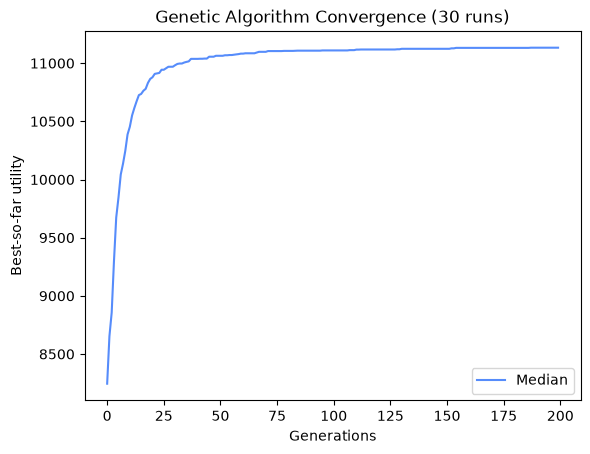

In [9]:
ga_history = np.array(ga_histories)
ga_best_so_far = np.maximum.accumulate(ga_history, axis=1)
ga_med = np.median(ga_best_so_far, axis=0)

plt.plot(ga_med, label="Median")
plt.xlabel("Generations")
plt.ylabel("Best-so-far utility")
plt.title("Genetic Algorithm Convergence (30 runs)")
plt.legend()
plt.show()


### Part 2: Advanced Metaheuristic Engineering
In this part, I have implemented an advanced population-based discrete metaheuristic, which is Genetic Algorithm and with Greddy Repair contrant handling. \
When changing the dataset, the local search might be not ideal, the first reason is that the local search only hit local optima, not global optima as it is only find a best solution and then in the next independent runs, it will show the result that equals value or less value to the previous results. From that I have used Genetic Algorithm to diversify the solution, not depending on the starting point to find the solution, so it solves the local optima problem. the output of the Genetic Algorithm is a list with 0 and 1, 0 is not choosing that model in that index and 1 is choosing that model in that index.

There are steps to introduce GA:
- The generate first population: "population" variable
- Evaluate fitness: "ga_fitness" function
- Tournament parent selection
- crossover and mutation

Moreover, I have applied Greddy Repair which checks if the solution is infeasible or feasible, if the solution is infeasible, delete the models from the lowest efficiency until the solution is feasible, which fixes all the solutions into all feasible solution.

For the result of running genetic algorithm, the best value of all solutions is 1116.0, the mean value is around 11122. The algorithm takes 14.23s to run all 30 independent runs, which is slower than the local search. However, the capacity used is [1741. 1099. 2222. 2083. 2306.] / [2100. 1100. 3300. 3700. 3600.], which does not use up all the capacities. Regarding the genetic convergence graph, it shows that the best-so-far value of the algorithm shoots up in early stage of genetic algorithm, however, from one point, it is slowly improving the best-so-far value from 11000 to around 11600, which the solutions are improving to get the better value.


In [10]:
ga_med

array([ 8245. ,  8652.5,  8856.5,  9296. ,  9673.5,  9845.5, 10043. ,
       10136. , 10246.5, 10387.5, 10453. , 10551. , 10615. , 10672.5,
       10725.5, 10735.5, 10763. , 10779.5, 10830.5, 10864.5, 10879. ,
       10908. , 10912. , 10916. , 10943.5, 10943.5, 10956. , 10969. ,
       10969. , 10969.5, 10982.5, 10993.5, 10997. , 10997. , 11005.5,
       11011. , 11015.5, 11037. , 11037. , 11037. , 11037. , 11038. ,
       11038. , 11039.5, 11039.5, 11055.5, 11055.5, 11055.5, 11063.5,
       11063.5, 11063.5, 11063.5, 11068. , 11068. , 11070. , 11070. ,
       11073. , 11075.5, 11078. , 11082. , 11082. , 11085. , 11085. ,
       11085. , 11085. , 11085. , 11091. , 11097.5, 11097.5, 11097.5,
       11097.5, 11104. , 11104. , 11104. , 11104. , 11104. , 11104. ,
       11104. , 11105.5, 11105.5, 11105.5, 11105.5, 11105.5, 11106.5,
       11107.5, 11107.5, 11107.5, 11107.5, 11107.5, 11107.5, 11107.5,
       11107.5, 11107.5, 11107.5, 11107.5, 11109.5, 11109.5, 11109.5,
       11109.5, 1110